# Sección 1: Importación de Librerías y Carga de Datos

En esta sección se importan las dependencias del proyecto, se carga el conjunto de datos con codificación `utf-8-sig`, se revisan las dimensiones y primeros registros, y se valida la presencia íntegra de las columnas del diccionario.

In [1]:
# Importación de librerías principales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
from IPython.display import display

# Configuración básica de visualización
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print(f"Pandas versión: {pd.__version__}")

Pandas versión: 3.0.6


In [2]:
# Carga del archivo CSV con codificación utf-8-sig
df = pd.read_csv("transacciones_bancarias_fraude.csv", encoding="utf-8-sig")

# Dimensiones del dataset
print(f"Dimensiones (filas, columnas): {df.shape}")

# Primeras 5 filas del dataset
df.head()

Dimensiones (filas, columnas): (30090, 13)


,id_transaccion,monto,hora_transaccion,distancia_ubicacion,frecuencia_transacciones,monto_promedio_cliente,dispositivo_nuevo,ubicacion_nueva,tipo_transaccion,canal,metodo_autenticacion,antiguedad_cliente_meses,fraude
0,TX010403,505.68,16,11.38,2,420.04,1,0,Pago,POS,Tarjeta,34,0
1,TX003473,97.93,17,6.50,4,58.77,0,0,Pago,Aplicación móvil,Clave,77,0
2,TX001435,38.36,16,15.65,2,55.39,0,0,Compra,POS,Tarjeta,76,0
3,TX007058,52.36,16,16.33,4,137.29,0,0,Retiro,Web,Biometría,31,0
4,TX011553,60.84,16,14.09,3,70.20,0,0,Compra,Aplicación móvil,Biometría,76,0


In [3]:
# Información general del DataFrame (tipos de datos y no nulos)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30090 entries, 0 to 30089
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_transaccion            30090 non-null  str    
 1   monto                     30090 non-null  float64
 2   hora_transaccion          30090 non-null  int64  
 3   distancia_ubicacion       29785 non-null  float64
 4   frecuencia_transacciones  30090 non-null  int64  
 5   monto_promedio_cliente    29604 non-null  float64
 6   dispositivo_nuevo         30090 non-null  int64  
 7   ubicacion_nueva           30090 non-null  int64  
 8   tipo_transaccion          30090 non-null  str    
 9   canal                     30090 non-null  str    
 10  metodo_autenticacion      29843 non-null  str    
 11  antiguedad_cliente_meses  30090 non-null  int64  
 12  fraude                    30090 non-null  int64  
dtypes: float64(3), int64(6), str(4)
memory usage: 3.0 MB


In [4]:
# Verificación de columnas del diccionario de datos
columnas_esperadas = [
    "id_transaccion", "monto", "hora_transaccion", "distancia_ubicacion",
    "frecuencia_transacciones", "monto_promedio_cliente", "dispositivo_nuevo",
    "ubicacion_nueva", "tipo_transaccion", "canal", "metodo_autenticacion",
    "antiguedad_cliente_meses", "fraude"
]

columnas_actuales = df.columns.tolist()
columnas_faltantes = [col for col in columnas_esperadas if col not in columnas_actuales]
columnas_extra = [col for col in columnas_actuales if col not in columnas_esperadas]

print(f"Columnas esperadas: {len(columnas_esperadas)} | Columnas detectadas: {len(columnas_actuales)}")
if not columnas_faltantes and not columnas_extra:
    print("✓ Verificación exitosa: Todas las columnas del diccionario están presentes.")
else:
    if columnas_faltantes:
        print(f"✗ Columnas faltantes: {columnas_faltantes}")
    if columnas_extra:
        print(f"✗ Columnas no esperadas: {columnas_extra}")

Columnas esperadas: 13 | Columnas detectadas: 13
✓ Verificación exitosa: Todas las columnas del diccionario están presentes.


# Sección 2: Análisis Exploratorio de Datos (EDA)

Exploración de la calidad de los datos, distribución de variables categóricas y numéricas, balance de la variable objetivo y detección de valores atípicos.

### 2.a Valores faltantes: conteo y porcentaje por columna

In [5]:
# Conteo y porcentaje de valores faltantes por columna
nulos = df.isnull().sum()
pct_nulos = (df.isnull().mean() * 100).round(2)
tabla_nulos = pd.DataFrame({"Faltantes": nulos, "Porcentaje (%)": pct_nulos})
display(tabla_nulos[tabla_nulos["Faltantes"] > 0])

,Faltantes,Porcentaje (%)
distancia_ubicacion,305,1.01
monto_promedio_cliente,486,1.62
metodo_autenticacion,247,0.82


**Interpretación:** Solo 3 variables presentan valores faltantes: `monto_promedio_cliente` (486 registros, 1,62 %), `distancia_ubicacion` (305, 1,01 %) y `metodo_autenticacion` (247, 0,82 %). Todos están por debajo del 2 %, por lo que no conviene eliminar filas: se imputarán (mediana en las numéricas por su asimetría y moda en la categórica). La imputación se ajustará solo con el conjunto de entrenamiento, dentro del pipeline, para evitar fuga de información.

### 2.b Duplicados exactos

In [6]:
# Conteo de registros duplicados exactos
num_duplicados = df.duplicated().sum()
print(f"Total de duplicados exactos: {num_duplicados}")

Total de duplicados exactos: 90


**Interpretación:** Se detectaron 90 registros duplicados exactos (≈0,30 %). Se eliminarán antes de dividir en entrenamiento y prueba; de lo contrario, una misma transacción podría caer en ambos conjuntos y las métricas saldrían infladas (data leakage).

### 2.c Distribución de variables categóricas

,Conteo,Porcentaje (%)
tipo_transaccion,,
Compra,14780,49.12
Pago,7120,23.66
Transferencia,4878,16.21
Retiro,3312,11.01


,Conteo,Porcentaje (%)
canal,,
Aplicación móvil,10433,34.67
POS,10266,34.12
Web,6925,23.01
Cajero,2466,8.20


,Conteo,Porcentaje (%)
metodo_autenticacion,,
Tarjeta,15424,51.26
Clave,5918,19.67
Biometría,5686,18.90
Token,2815,9.36
NaN,247,0.82


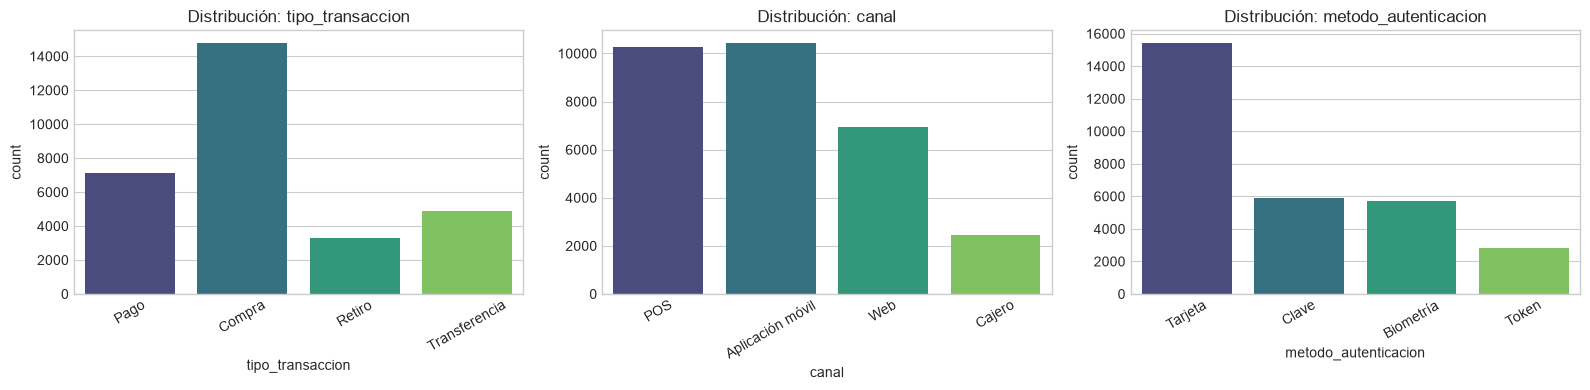

In [7]:
# Distribución de variables categóricas con conteos, porcentajes y countplots
cat_cols = ["tipo_transaccion", "canal", "metodo_autenticacion"]

for col in cat_cols:
    conteo = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    display(pd.DataFrame({"Conteo": conteo, "Porcentaje (%)": pct}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue=col, ax=axes[i], palette="viridis", legend=False)
    axes[i].set_title(f"Distribución: {col}")
    axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Interpretación:** `tipo_transaccion` está dominada por Compra (49,12 %), seguida de Pago (23,66 %), Transferencia (16,21 %) y Retiro (11,01 %). En `canal` predominan Aplicación móvil (34,67 %) y POS (34,12 %), con Web (23,01 %) y Cajero (8,20 %) menos frecuentes. En `metodo_autenticacion` domina Tarjeta (51,26 %); el resto se reparte entre Clave, Biometría y Token (9,36 %), y hay 0,82 % de nulos. Todas tienen pocas categorías y ninguna con frecuencia insignificante, por lo que One-Hot Encoding es adecuado y no genera demasiadas columnas.

### 2.d Variables numéricas: estadísticas descriptivas e histogramas

,monto,hora_transaccion,distancia_ubicacion,frecuencia_transacciones,monto_promedio_cliente,dispositivo_nuevo,ubicacion_nueva,antiguedad_cliente_meses,fraude
count,30090.00,30090.00,29785.00,30090.00,29604.00,30090.00,30090.00,30090.00,30090.00
mean,106.72,13.62,11.79,2.20,80.37,0.09,0.09,53.83,0.03
std,147.87,4.79,21.02,1.71,53.74,0.28,0.28,34.82,0.16
min,2.58,0.00,0.00,0.00,7.03,0.00,0.00,1.00,0.00
25%,39.74,11.00,2.76,1.00,44.87,0.00,0.00,28.00,0.00
50%,69.56,14.00,6.69,2.00,67.07,0.00,0.00,47.00,0.00
75%,123.48,17.00,13.60,3.00,100.59,0.00,0.00,72.00,0.00
max,5000.00,23.00,500.00,15.00,1269.98,1.00,1.00,240.00,1.00


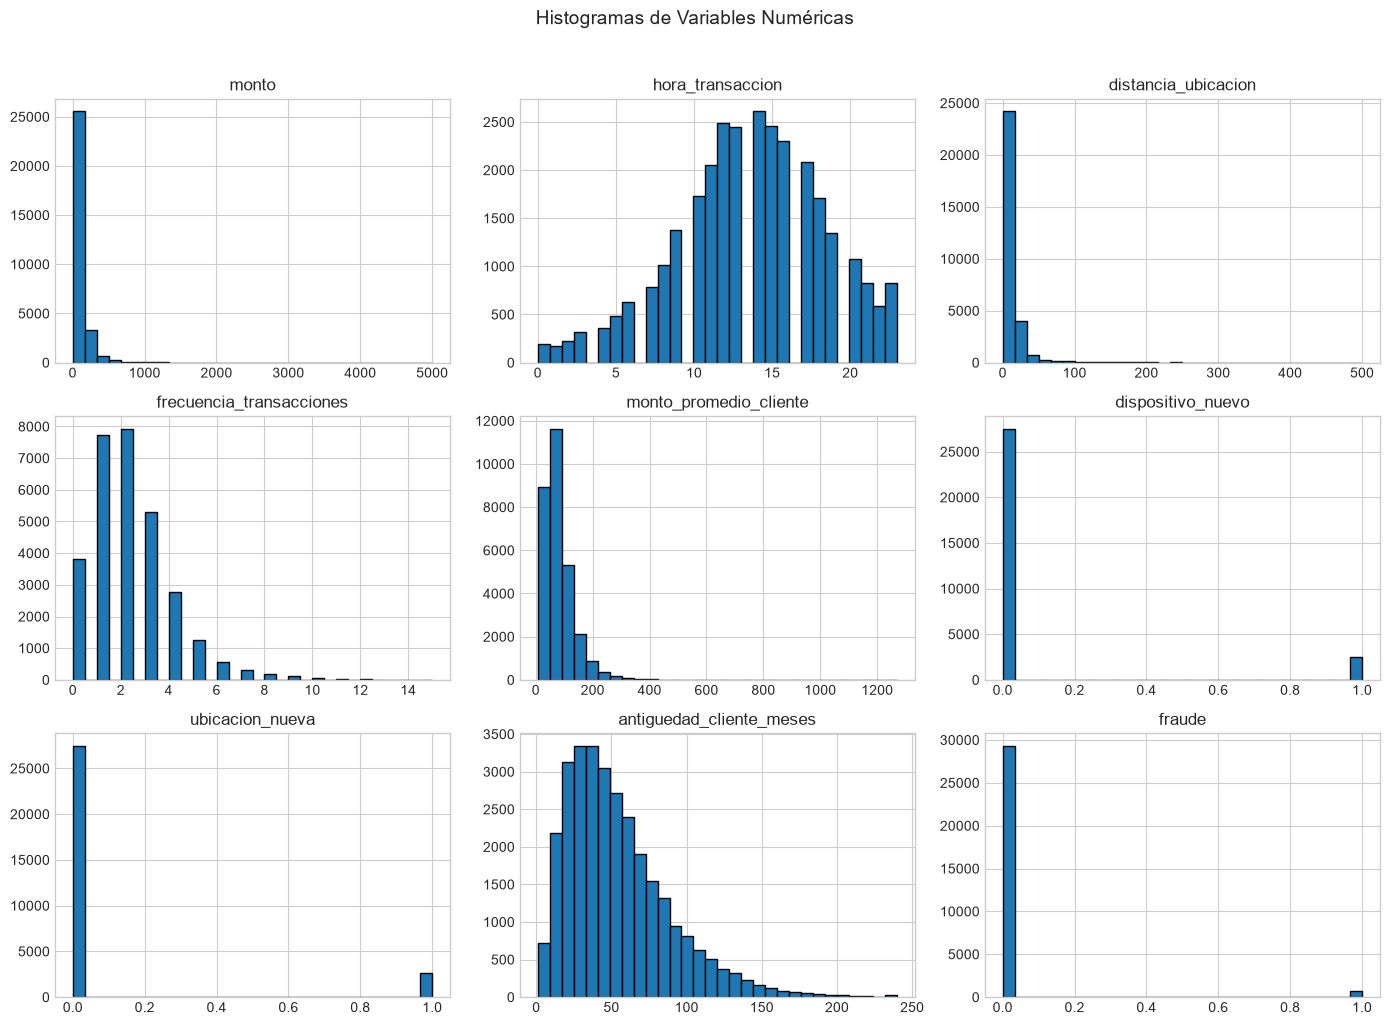

In [8]:
# Estadísticas descriptivas de variables numéricas
display(df.describe().round(2))

# Histogramas de distribución para variables numéricas
num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols].hist(figsize=(14, 10), bins=30, edgecolor="black", grid=True)
plt.suptitle("Histogramas de Variables Numéricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Interpretación:** `monto`, `distancia_ubicacion`, `monto_promedio_cliente` y `antiguedad_cliente_meses` presentan asimetría positiva: la media supera a la mediana (por ejemplo, monto 106,72 vs 69,56; distancia 11,79 vs 6,69) y existen valores muy altos (monto máximo 5.000, distancia máxima 500 km). `hora_transaccion` se concentra entre las 11 y las 18 h (mediana 14), con poca actividad en la madrugada. `frecuencia_transacciones` tiene mediana 2 y máximo 15. `dispositivo_nuevo` y `ubicacion_nueva` son binarias y valen 1 en cerca del 9 % de los casos. Como las escalas son muy distintas (monto hasta 5.000 frente a variables 0/1), se aplicará estandarización, necesaria para Regresión Logística, KNN, SVM y MLP.

### 2.e Proporción de fraude vs legítimas

,Conteo,Porcentaje (%)
fraude,,
0,29321,97.44
1,769,2.56


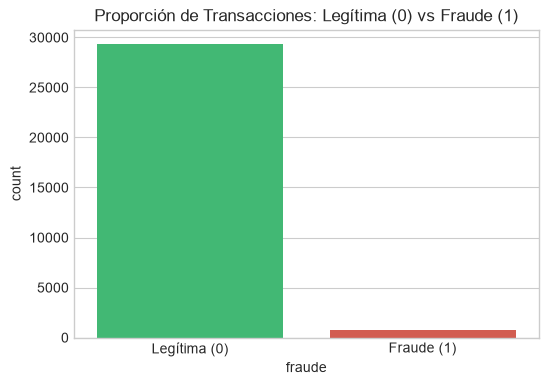

In [9]:
# Conteo y porcentaje de la variable objetivo (fraude)
conteo_fraude = df["fraude"].value_counts()
pct_fraude = (df["fraude"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"Conteo": conteo_fraude, "Porcentaje (%)": pct_fraude}))

# Gráfico de barras de la variable objetivo
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="fraude", hue="fraude", palette=["#2ecc71", "#e74c3c"], legend=False)
ax.set_title("Proporción de Transacciones: Legítima (0) vs Fraude (1)")
ax.set_xticks([0, 1], labels=["Legítima (0)", "Fraude (1)"])
plt.show()

**Interpretación:** Hay 29.321 transacciones legítimas (97,44 %) y 769 fraudulentas (2,56 %): una relación aproximada de 38 a 1, lo que confirma un problema de clases desbalanceadas. Un modelo que clasificara todo como legítimo tendría un 97,44 % de Accuracy sin detectar ningún fraude (Recall = 0), por eso el análisis se basará en Recall, Precision, F1 y AUC-ROC, usando división y validación cruzada estratificadas y un tratamiento explícito del desbalance.

### 2.f Detección de valores atípicos (regla IQR y boxplots)

,Q1,Q3,IQR,Límite Inf,Límite Sup,Atípicos,Porcentaje (%)
Variable,,,,,,,
monto,39.74,123.48,83.73,-85.86,249.08,2236,7.43
distancia_ubicacion,2.76,13.60,10.84,-13.50,29.86,1907,6.40
frecuencia_transacciones,1.00,3.00,2.00,-2.00,6.00,732,2.43


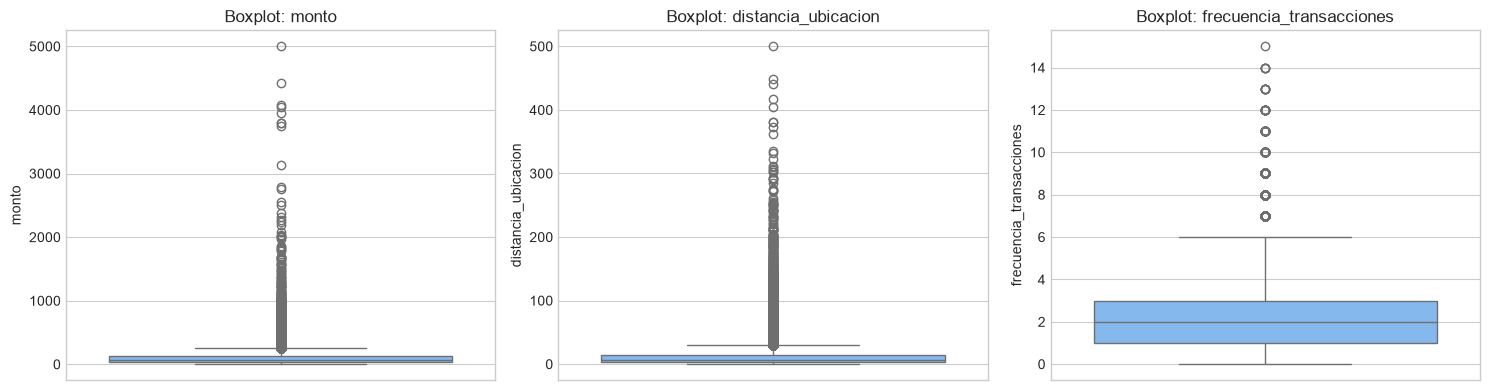

In [10]:
# Detección de valores atípicos por regla IQR
cols_atipicos = ["monto", "distancia_ubicacion", "frecuencia_transacciones"]
iqr_summary = []
for col in cols_atipicos:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    outliers = ((s < lim_inf) | (s > lim_sup)).sum()
    pct = (outliers / len(s)) * 100
    iqr_summary.append({
        "Variable": col, "Q1": round(q1, 2), "Q3": round(q3, 2), "IQR": round(iqr, 2),
        "Límite Inf": round(lim_inf, 2), "Límite Sup": round(lim_sup, 2),
        "Atípicos": outliers, "Porcentaje (%)": round(pct, 2)
    })
display(pd.DataFrame(iqr_summary).set_index("Variable"))

# Boxplots para visualización de atípicos
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(cols_atipicos):
    sns.boxplot(y=df[col], ax=axes[i], color="#74b9ff")
    axes[i].set_title(f"Boxplot: {col}")
plt.tight_layout()
plt.show()

**Interpretación:** Por la regla del IQR hay 2.236 atípicos en `monto` (7,43 %, límite superior 249,08), 1.907 en `distancia_ubicacion` (6,40 %, límite 29,86) y 732 en `frecuencia_transacciones` (2,43 %, límite 6). No se eliminarán: montos altos, distancias grandes y ráfagas de transacciones son comportamientos típicos de fraude, así que contienen información que el modelo debe aprender. Como los atípicos (7,43 % en monto) superan la tasa de fraude (2,56 %), no todos son fraudes: también hay clientes legítimos con compras grandes o lejanas.

## Sección 2.1: Análisis Bivariado respecto a Fraude

Evaluación de la relación de cada variable explicativa con respecto a la variable objetivo `fraude`.

### 2.1.a Tasa de fraude (%) por variables categóricas y binarias

In [11]:
# Tasa de fraude (%) por categorías y variables binarias
vars_cat = ["tipo_transaccion", "canal", "metodo_autenticacion", "dispositivo_nuevo", "ubicacion_nueva"]

for var in vars_cat:
    tabla = df.groupby(var, dropna=False)["fraude"].agg(
        Total="count",
        Casos_Fraude="sum",
        Tasa_Fraude_Pct=lambda x: (x.mean() * 100).round(2)
    )
    display(tabla)

,Total,Casos_Fraude,Tasa_Fraude_Pct
tipo_transaccion,,,
Compra,14780,270,1.83
Pago,7120,52,0.73
Retiro,3312,174,5.25
Transferencia,4878,273,5.60


,Total,Casos_Fraude,Tasa_Fraude_Pct
canal,,,
Aplicación móvil,10433,252,2.42
Cajero,2466,99,4.01
POS,10266,109,1.06
Web,6925,309,4.46


,Total,Casos_Fraude,Tasa_Fraude_Pct
metodo_autenticacion,,,
Biometría,5686,60,1.06
Clave,5918,272,4.60
Tarjeta,15424,358,2.32
Token,2815,72,2.56
NaN,247,7,2.83


,Total,Casos_Fraude,Tasa_Fraude_Pct
dispositivo_nuevo,,,
0,27532,418,1.52
1,2558,351,13.72


,Total,Casos_Fraude,Tasa_Fraude_Pct
ubicacion_nueva,,,
0,27470,307,1.12
1,2620,462,17.63


### 2.1.b Boxplots por condición de fraude (escala logarítmica en monto y distancia)

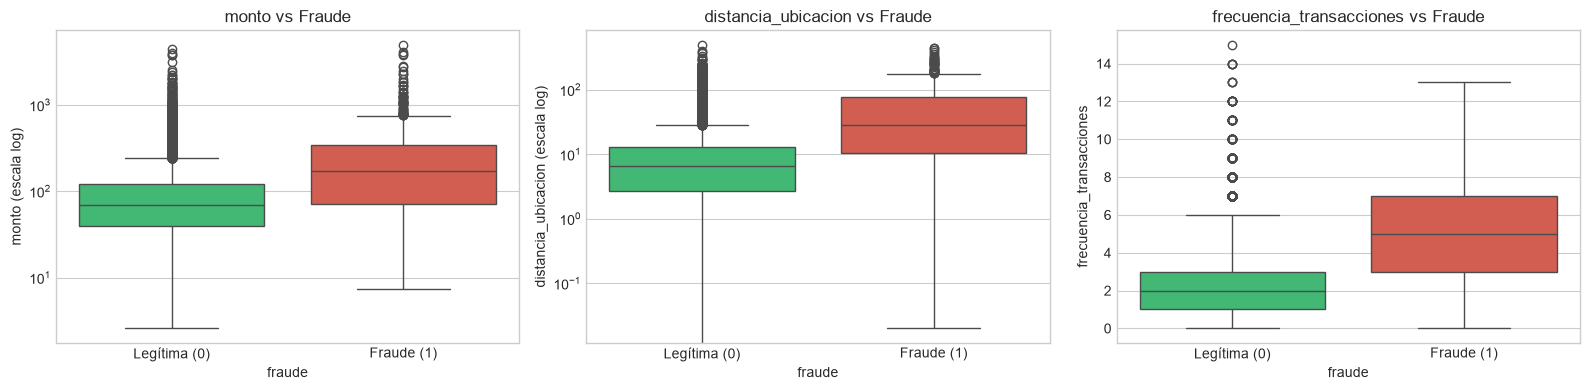

In [12]:
# Boxplots comparativos respecto a fraude (0 vs 1) con escala log en monto y distancia
cols_biv = ["monto", "distancia_ubicacion", "frecuencia_transacciones"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, col in enumerate(cols_biv):
    sns.boxplot(data=df, x="fraude", y=col, hue="fraude", ax=axes[i], palette=["#2ecc71", "#e74c3c"], legend=False)
    axes[i].set_title(f"{col} vs Fraude")
    axes[i].set_xticks([0, 1], labels=["Legítima (0)", "Fraude (1)"])
    if col in ["monto", "distancia_ubicacion"]:
        axes[i].set_yscale("log")
        axes[i].set_ylabel(f"{col} (escala log)")

plt.tight_layout()
plt.show()

### 2.1.c Tasa de fraude por hora de la transacción

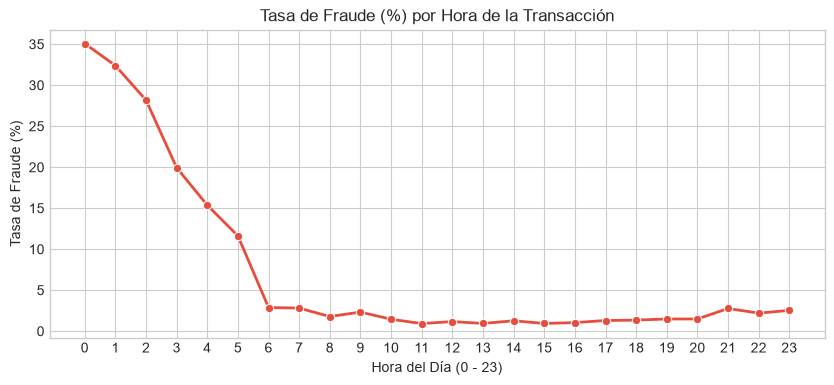

In [13]:
# Gráfico de línea: tasa de fraude (%) por hora de la transacción
tasa_hora = (df.groupby("hora_transaccion")["fraude"].mean() * 100).reset_index()

plt.figure(figsize=(10, 4))
sns.lineplot(data=tasa_hora, x="hora_transaccion", y="fraude", marker="o", color="#e74c3c", linewidth=2)
plt.title("Tasa de Fraude (%) por Hora de la Transacción")
plt.xlabel("Hora del Día (0 - 23)")
plt.ylabel("Tasa de Fraude (%)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

### Interpretación del análisis bivariado (fraude vs. variables)

**Variables binarias.** Son las que más separan el fraude. Con `ubicacion_nueva` = 1 la tasa de fraude es 17,63 % (462 de 2.620 casos) frente a 1,12 % cuando es 0. Con `dispositivo_nuevo` = 1 es 13,72 % (351 de 2.558) frente a 1,52 %. Ambas multiplican entre 5 y 7 veces la tasa global (2,56 %) y concentran la mayoría de los fraudes (462 y 351 de 769).

**Variables categóricas.** El fraude es más frecuente en Transferencia (5,60 %) y Retiro (5,25 %) que en Compra (1,83 %) y Pago (0,73 %). Por canal, Web (4,46 %) y Cajero (4,01 %) superan a Aplicación móvil (2,42 %) y POS (1,06 %). Por método de autenticación, Clave (4,60 %) es el más riesgoso y Biometría (1,06 %) el más seguro. Los nulos de `metodo_autenticacion` (2,83 %) se comportan parecido a la tasa global, por lo que imputarlos no distorsiona el análisis.

**Variables numéricas.** Las transacciones fraudulentas tienen una mediana mayor en `monto` (aprox. 170 vs 70 USD), `distancia_ubicacion` (aprox. 28 vs 7 km) y `frecuencia_transacciones` (5 vs 2 en 24 h). Aun así, las cajas se solapan, así que ninguna variable separa las clases por sí sola: se necesita un modelo que las combine.

**Hora del día.** La tasa de fraude es muy alta en la madrugada (aprox. 35 % a las 0 h y baja hasta cerca de 12 % a las 5 h) y se estabiliza entre 1 % y 3 % desde las 6 h. La hora aporta información, pero su relación no es lineal.

**Conclusión.** Los fraudes se asocian con ubicación y dispositivo nuevos, transferencias y retiros, canales Web y Cajero, madrugada, mayor monto, mayor distancia y más transacciones en 24 h. Esto respalda usar modelos capaces de capturar combinaciones de variables, como Random Forest, además de la Regresión Logística como línea base.

# Sección 3: Preparación de Datos y Preprocesamiento

En esta sección se limpian los registros duplicados, se exporta el dataset depurado, se dividen los datos en conjuntos de entrenamiento y prueba mediante estratificación, y se define el transformador de columnas (`ColumnTransformer`) sin ajustarlo, evitando cualquier tipo de fuga de información (*data leakage*).

### 3.1 Limpieza de duplicados y exportación del dataset

In [14]:
# (1) Eliminación de duplicados exactos
df = df.drop_duplicates()
print(f"Filas restantes tras eliminar duplicados: {df.shape[0]}")

# (2) Guardar dataset procesado
df.to_csv("dataset_procesado.csv", encoding="utf-8-sig", index=False)
print("Dataset procesado guardado exitosamente en 'dataset_procesado.csv'.")

Filas restantes tras eliminar duplicados: 30000
Dataset procesado guardado exitosamente en 'dataset_procesado.csv'.


### 3.2 Separación de variables y partición Train / Test (Estratificada)

In [15]:
from sklearn.model_selection import train_test_split

# (3) Separar predictoras (X) y objetivo (y), excluyendo 'id_transaccion'
X = df.drop(columns=["id_transaccion", "fraude"])
y = df["fraude"]

# (4) División estratificada 80/20 con random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Tamaños de los conjuntos
print(f"Tamaño X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"Tamaño X_test:  {X_test.shape}  | y_test:  {y_test.shape}")

# Proporción de fraude en train y test
prop_train = (y_train.value_counts(normalize=True) * 100).round(2)
prop_test = (y_test.value_counts(normalize=True) * 100).round(2)
print("\nProporción de fraude en Train (%):")
print(prop_train.to_string())
print("\nProporción de fraude en Test (%):")
print(prop_test.to_string())

Tamaño X_train: (24000, 11) | y_train: (24000,)
Tamaño X_test:  (6000, 11)  | y_test:  (6000,)

Proporción de fraude en Train (%):
fraude
0    97.45
1     2.55

Proporción de fraude en Test (%):
fraude
0    97.45
1     2.55


### 3.3 Definición del ColumnTransformer (Sin ajuste previo)

> **Prevención de Data Leakage:** El `ColumnTransformer` se define **sin ajustarlo** (`fit` o `fit_transform`). El cálculo de estadísticas (medianas para imputación, medias y varianzas para estandarización, y categorías para one-hot encoding) se realizará estrictamente sobre los datos de entrenamiento (`X_train`) dentro de los pipelines de modelado.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# (5) Definición de listas de columnas según su naturaleza
num_cols = [
    "monto", "hora_transaccion", "distancia_ubicacion",
    "frecuencia_transacciones", "monto_promedio_cliente", "antiguedad_cliente_meses"
]
cat_cols = ["tipo_transaccion", "canal", "metodo_autenticacion"]
bin_cols = ["dispositivo_nuevo", "ubicacion_nueva"]

# Pipeline para variables numéricas (mediana + estandarización)
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline para variables categóricas (moda + OneHotEncoding)
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Ensamblado del preprocesador mediante ColumnTransformer (sin ajustar)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
        ("bin", "passthrough", bin_cols)
    ],
    remainder="drop"
)

print("ColumnTransformer definido exitosamente (sin ajustar):")
display(preprocessor)

ColumnTransformer definido exitosamente (sin ajustar):


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

### Interpretación de la preparación de datos

Se eliminaron 90 registros duplicados exactos (0,30 %), quedando 30.000 transacciones. Esto evita que una misma transacción aparezca a la vez en entrenamiento y prueba, lo que inflaría las métricas. Luego se separaron los predictores X (11 variables, sin `id_transaccion`, que es solo un identificador) de la variable objetivo `fraude`.

La división en entrenamiento (24.000) y prueba (6.000) es estratificada 80/20: la proporción de fraude es 2,55 % en ambos conjuntos, así que la prueba representa bien el desbalance real. El conjunto de prueba no se toca hasta la evaluación final.

El preprocesamiento se definió con un ColumnTransformer: las variables numéricas se imputan con la mediana (robusta a valores atípicos) y se estandarizan; las categóricas se imputan con la moda y se codifican con One-Hot; las binarias pasan sin cambios. Todavía no se ajusta: se hará solo con los datos de entrenamiento, dentro de los pipelines, para que nada del conjunto de prueba influya en el modelo (sin data leakage).

# Sección 4: Tratamiento del Desbalance de Clases

**Estrategia y ausencia de data leakage:**  
El dataset presenta un marcado desbalance (~97.5% legítimas vs 2.5% fraudes). La estrategia principal es `class_weight="balanced"` directamente en los clasificadores que lo soporten (Logistic Regression, Random Forest, SVC), ya que ajusta los pesos durante el entrenamiento sin modificar el conjunto de datos. SMOTE se ofrece como alternativa comparable, integrado en un `imblearn.Pipeline` que garantiza que el remuestreo se aplica **únicamente sobre los datos de entrenamiento dentro de cada fold**, evitando cualquier fuga de información hacia el conjunto de validación.

In [17]:
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

def construir_pipeline(modelo, usar_smote=False):
    """
    Construye un pipeline con preprocesamiento + (SMOTE opcional) + modelo.
    - usar_smote=False: sklearn Pipeline  [preprocessor -> modelo]
    - usar_smote=True : imblearn Pipeline [preprocessor -> SMOTE -> modelo]
      SMOTE se aplica solo sobre los datos de train dentro de cada fold.
    """
    if usar_smote:
        return ImbPipeline(steps=[
            ("preprocesamiento", preprocessor),
            ("smote", SMOTE(random_state=42)),
            ("modelo", modelo)
        ])
    else:
        return SkPipeline(steps=[
            ("preprocesamiento", preprocessor),
            ("modelo", modelo)
        ])

print("Función construir_pipeline() definida correctamente.")
print("  - usar_smote=False -> sklearn Pipeline (preprocesamiento + modelo)")
print("  - usar_smote=True  -> imblearn Pipeline (preprocesamiento + SMOTE + modelo)")

Función construir_pipeline() definida correctamente.
  - usar_smote=False -> sklearn Pipeline (preprocesamiento + modelo)
  - usar_smote=True  -> imblearn Pipeline (preprocesamiento + SMOTE + modelo)


### Interpretación del tratamiento del desbalance

Con solo un 2,55 % de fraudes, entrenar sin corregir el desbalance llevaría a modelos que casi siempre predicen "legítima". Como estrategia principal se usa `class_weight="balanced"`, que penaliza más los errores sobre la clase fraude sin modificar los datos. Como alternativa comparable se usa SMOTE, que genera fraudes sintéticos. Ambas estrategias se aplican únicamente dentro de los folds de entrenamiento mediante pipelines, por lo que el conjunto de prueba y los folds de validación nunca se remuestrean ni influyen en el preprocesamiento (sin data leakage).

# Sección 5: Entrenamiento y Validación Cruzada

Se evalúan 5 configuraciones mediante `StratifiedKFold(n_splits=5)` y `cross_validate` usando solo `X_train` / `y_train`. El conjunto de prueba (`X_test`) **no se toca** en esta sección.

In [18]:
import time
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Métricas y esquema de validación cruzada estratificada
scoring = ["roc_auc", "recall", "precision", "f1", "accuracy"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Definición de las 5 configuraciones a evaluar
configs = [
    ("LR_balanced", construir_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
    )),
    ("DT_balanced", construir_pipeline(
        DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=42)
    )),
    ("RF_balanced", construir_pipeline(
        RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=42)
    )),
    ("LR_SMOTE", construir_pipeline(
        LogisticRegression(max_iter=1000, random_state=42), usar_smote=True
    )),
    ("RF_SMOTE", construir_pipeline(
        RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42), usar_smote=True
    )),
]

# Entrenamiento con validación cruzada (solo sobre X_train / y_train)
resultados = []
for nombre, pipe in configs:
    print(f"  [{nombre}] Iniciando cross_validate...")
    t0 = time.time()
    cv_res = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring=scoring,
        n_jobs=-1, return_train_score=False
    )
    elapsed = time.time() - t0
    fila = {"Modelo": nombre, "Tiempo_s": round(elapsed, 1)}
    for met in scoring:
        vals = cv_res[f"test_{met}"]
        fila[f"{met}_mean"] = round(vals.mean(), 4)
        fila[f"{met}_std"]  = round(vals.std(),  4)
    resultados.append(fila)
    print(f"    -> Completado en {elapsed:.1f}s")

# Tabla resumen de resultados de validación cruzada
df_cv = pd.DataFrame(resultados).set_index("Modelo")
print("\n=== Resultados de Validación Cruzada (5-Fold) ===\n")
display(df_cv.round(4))

  [LR_balanced] Iniciando cross_validate...
    -> Completado en 4.8s
  [DT_balanced] Iniciando cross_validate...
    -> Completado en 3.7s
  [RF_balanced] Iniciando cross_validate...
    -> Completado en 8.0s
  [LR_SMOTE] Iniciando cross_validate...
    -> Completado en 0.9s
  [RF_SMOTE] Iniciando cross_validate...
    -> Completado en 12.1s

=== Resultados de Validación Cruzada (5-Fold) ===



,Tiempo_s,roc_auc_mean,roc_auc_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std,accuracy_mean,accuracy_std
Modelo,,,,,,,,,,,
LR_balanced,4.8,0.8837,0.0190,0.8007,0.0177,0.2663,0.0075,0.3996,0.0101,0.9386,0.0017
DT_balanced,3.7,0.8530,0.0214,0.7533,0.0318,0.2315,0.0189,0.3539,0.0249,0.9296,0.0056
RF_balanced,8.0,0.8844,0.0136,0.6700,0.0295,0.4236,0.0324,0.5179,0.0239,0.9681,0.0031
LR_SMOTE,0.9,0.8851,0.0195,0.7958,0.0173,0.2449,0.0089,0.3744,0.0108,0.9321,0.0029
RF_SMOTE,12.1,0.8837,0.0107,0.5850,0.0290,0.4222,0.0315,0.4891,0.0197,0.9688,0.0028


### Interpretación de la validación cruzada (5-Fold estratificada)

**AUC-ROC.** Regresión Logística, Random Forest y sus variantes con SMOTE obtienen un AUC-ROC casi igual (≈0,884–0,885). Las diferencias son menores que la desviación estándar entre folds (≈0,01–0,02), así que no permiten distinguir un ganador por ese criterio. El Árbol de Decisión es el más bajo (0,853).

**Recall (fraudes detectados).** La Regresión Logística es la que más fraudes detecta: 0,80 con `class_weight` y 0,80 con SMOTE. Le sigue el Árbol de Decisión (0,75). Random Forest detecta menos (0,67 con `class_weight` y 0,585 con SMOTE), es decir, deja pasar entre un 33 % y un 41 % de los fraudes con el umbral de 0,5.

**Precision y F1.** Random Forest es mucho más preciso (≈0,42 frente a ≈0,25 de la Regresión Logística) y obtiene el mejor F1 (0,52 con `class_weight`). La Regresión Logística genera más falsas alarmas: aproximadamente 3 de cada 4 alertas serían transacciones legítimas.

**Accuracy.** Varía entre 0,93 y 0,97, pero un modelo que clasifique todo como legítimo ya obtendría 0,9745. Por eso no se usa para decidir: los modelos tienen una exactitud menor que ese caso trivial y, a diferencia de él, sí detectan fraudes.

**Estrategia de desbalance.** SMOTE no mejora a `class_weight="balanced"`: en Regresión Logística los resultados son equivalentes y en Random Forest el Recall empeora (0,585 frente a 0,67). Se mantiene `class_weight` como estrategia principal, que además es más simple y no crea datos sintéticos.

**Conclusión parcial.** El criterio principal del caso es reducir los falsos negativos, por lo que la Regresión Logística y el Random Forest con `class_weight` son los candidatos. La Regresión Logística maximiza el Recall; el Random Forest ofrece el mejor equilibrio entre Precision y Recall. Para decidir con justicia se comparará el rendimiento de ambos ajustando el umbral de decisión, usando solo el conjunto de entrenamiento.

# Sección 6: Comparación de Modelos

Consolidación de las métricas de validación cruzada en formato `media ± desviación estándar` y visualización comparativa mediante gráfico de barras agrupadas.

### 6.1 Tabla comparativa de modelos (ordenada por Recall y ROC-AUC)

In [19]:
# Construcción de df_comparativo a partir de df_cv sin reentrenar
metricas = ["roc_auc", "recall", "precision", "f1", "accuracy"]

# Ordenamiento por recall descendente y luego roc_auc descendente
df_sorted = df_cv.sort_values(by=["recall_mean", "roc_auc_mean"], ascending=[False, False])

# Formateo a media ± desviación estándar con 4 decimales
df_comparativo = pd.DataFrame(index=df_sorted.index)
for met in metricas:
    df_comparativo[met] = df_sorted.apply(
        lambda r: f"{r[f'{met}_mean']:.4f} ± {r[f'{met}_std']:.4f}", axis=1
    )

display(df_comparativo)

,roc_auc,recall,precision,f1,accuracy
Modelo,,,,,
LR_balanced,0.8837 ± 0.0190,0.8007 ± 0.0177,0.2663 ± 0.0075,0.3996 ± 0.0101,0.9386 ± 0.0017
LR_SMOTE,0.8851 ± 0.0195,0.7958 ± 0.0173,0.2449 ± 0.0089,0.3744 ± 0.0108,0.9321 ± 0.0029
DT_balanced,0.8530 ± 0.0214,0.7533 ± 0.0318,0.2315 ± 0.0189,0.3539 ± 0.0249,0.9296 ± 0.0056
RF_balanced,0.8844 ± 0.0136,0.6700 ± 0.0295,0.4236 ± 0.0324,0.5179 ± 0.0239,0.9681 ± 0.0031
RF_SMOTE,0.8837 ± 0.0107,0.5850 ± 0.0290,0.4222 ± 0.0315,0.4891 ± 0.0197,0.9688 ± 0.0028


### 6.2 Gráfico de barras agrupadas por métrica y modelo

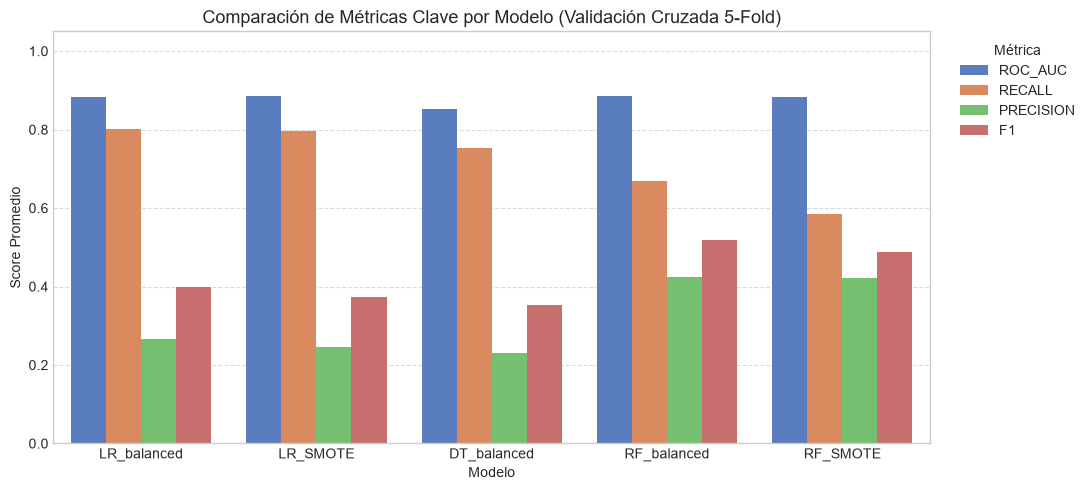

In [20]:
# Gráfico de barras agrupadas para roc_auc, recall, precision y f1
metricas_plot = ["roc_auc", "recall", "precision", "f1"]
df_plot = df_sorted[[f"{m}_mean" for m in metricas_plot]].reset_index()
df_plot.columns = ["Modelo"] + [m.upper() for m in metricas_plot]

df_plot_melted = df_plot.melt(id_vars="Modelo", var_name="Métrica", value_name="Score")

plt.figure(figsize=(11, 5))
sns.barplot(data=df_plot_melted, x="Modelo", y="Score", hue="Métrica", palette="muted")
plt.title("Comparación de Métricas Clave por Modelo (Validación Cruzada 5-Fold)", fontsize=13)
plt.xlabel("Modelo")
plt.ylabel("Score Promedio")
plt.ylim(0, 1.05)
plt.legend(title="Métrica", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Interpretación de la comparación de modelos

**Visión general.** Cuatro de los cinco modelos tienen un AUC-ROC prácticamente igual (0,8837–0,8851); solo el Árbol de Decisión queda por debajo (0,8530). Como esas diferencias son menores que la desviación entre folds (≈0,01–0,02), el AUC-ROC no basta para elegir: la decisión depende del equilibrio entre Recall y Precision.

**Regresión Logística (LR_balanced).** Es la que más fraudes detecta (Recall 0,8007 ± 0,0177), pero con la menor Precision entre los modelos competitivos (0,2663): aproximadamente tres de cada cuatro alertas serían falsas alarmas. Su F1 es 0,3996.

**Random Forest (RF_balanced).** Tiene el mejor F1 (0,5179) y una Precision de 0,4236, con un Recall de 0,6700: deja pasar cerca de un tercio de los fraudes con el umbral por defecto de 0,5, a cambio de generar menos falsas alarmas. Su accuracy (0,9681) es la más alta junto con RF_SMOTE, pero no es un criterio válido en este caso: clasificar todo como legítimo ya daría 0,9745.

**Árbol de Decisión.** Tiene el menor AUC-ROC (0,8530) y la menor Precision (0,2315), sin ventaja en Recall frente a la Regresión Logística. Se descarta.

**SMOTE.** No supera a `class_weight="balanced"`: en Regresión Logística los resultados son equivalentes (Recall 0,7958 frente a 0,8007) y en Random Forest el Recall empeora (0,5850 frente a 0,6700). Se descarta porque no aporta mejora y añade complejidad al generar datos sintéticos.

**Candidatos finales.** LR_balanced y RF_balanced. El caso prioriza reducir los falsos negativos, pero ambos se compararán en igualdad de condiciones ajustando el umbral de decisión con predicciones de validación cruzada sobre el conjunto de entrenamiento, sin usar el conjunto de prueba.

# Sección 7: Selección y Evaluación Final del Modelo

Selección del umbral óptimo con validación cruzada OOF (sin tocar `X_test`), elección del modelo final y evaluación única sobre el conjunto de prueba.

### 7.1 Probabilidades OOF y umbral óptimo por candidato (solo sobre X_train)

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_recall_curve, roc_auc_score,
                             recall_score, precision_score, f1_score,
                             accuracy_score, roc_curve, classification_report)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
MIN_RECALL = 0.80  # Umbral mínimo de recall exigido

# Pipelines candidatos (mismas configuraciones de la Sección 5)
candidatos = {
    "LR_balanced": construir_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
    ),
    "RF_balanced": construir_pipeline(
        RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                               class_weight="balanced_subsample", n_jobs=-1, random_state=42)
    ),
}

# (1) Probabilidades OOF mediante cross_val_predict
# (2) Umbral que maximiza Precision exigiendo Recall >= 0.80
resultados_umbral = []
probs_oof = {}
for nombre, pipe in candidatos.items():
    print(f"  cross_val_predict: {nombre}...")
    proba = cross_val_predict(pipe, X_train, y_train, cv=cv,
                               method="predict_proba", n_jobs=-1)[:, 1]
    probs_oof[nombre] = proba

    prec_arr, rec_arr, thresh_arr = precision_recall_curve(y_train, proba)
    mask = rec_arr[:-1] >= MIN_RECALL  # Filtrar por recall mínimo
    if mask.any():
        best_idx  = np.argmax(prec_arr[:-1][mask])
        umbral_opt = thresh_arr[mask][best_idx]
        rec_opt    = rec_arr[:-1][mask][best_idx]
        prec_opt   = prec_arr[:-1][mask][best_idx]
        f1_opt     = 2 * prec_opt * rec_opt / (prec_opt + rec_opt + 1e-9)
    else:
        umbral_opt, rec_opt, prec_opt, f1_opt = np.nan, np.nan, np.nan, np.nan

    resultados_umbral.append({
        "Modelo": nombre,
        "Umbral": round(float(umbral_opt), 4),
        "Recall (CV-OOF)": round(float(rec_opt), 4),
        "Precision (CV-OOF)": round(float(prec_opt), 4),
        "F1 (CV-OOF)": round(float(f1_opt), 4),
    })
    print(f"    -> umbral={umbral_opt:.4f} | recall={rec_opt:.4f} | prec={prec_opt:.4f} | f1={f1_opt:.4f}")

df_umbral = pd.DataFrame(resultados_umbral).set_index("Modelo")
display(df_umbral)

  cross_val_predict: LR_balanced...
    -> umbral=0.5082 | recall=0.8007 | prec=0.2748 | f1=0.4092
  cross_val_predict: RF_balanced...
    -> umbral=0.1520 | recall=0.8007 | prec=0.2701 | f1=0.4040


,Umbral,Recall (CV-OOF),Precision (CV-OOF),F1 (CV-OOF)
Modelo,,,,
LR_balanced,0.5082,0.8007,0.2748,0.4092
RF_balanced,0.1520,0.8007,0.2701,0.4040


### 7.2 Selección del modelo final

In [22]:
# (3) Modelo final: mayor Precision con Recall >= 0.80 en validación cruzada OOF
mejor_nombre = df_umbral["Precision (CV-OOF)"].idxmax()
umbral_final  = float(df_umbral.loc[mejor_nombre, "Umbral"])
print(f"Modelo final seleccionado: {mejor_nombre}")
print(f"Umbral óptimo (OOF):       {umbral_final}")

Modelo final seleccionado: LR_balanced
Umbral óptimo (OOF):       0.5082


### 7.3 Justificación de la selección

Con el umbral ajustado para alcanzar Recall ≥ 0,80 en las predicciones fuera de muestra (validación cruzada sobre entrenamiento), ambos candidatos quedan prácticamente empatados: LR_balanced (umbral 0,5082; Precision 0,2748; F1 0,4092) y RF_balanced (umbral 0,1520; Precision 0,2701; F1 0,4040). La diferencia de 0,0047 en Precision es menor que la variabilidad entre folds observada en la Sección 5, por lo que no es relevante. Se elige LR_balanced por desempate: ofrece la misma capacidad de detección con un modelo más simple, rápido y explicable. La ventaja aparente de Random Forest en F1 con el umbral 0,5 (Sección 6) se debía a que operaba en otro punto de la curva, no a una mejor discriminación. El umbral se eligió solo con datos de entrenamiento; X_test no se usó para ninguna decisión.

### 7.4 Entrenamiento final con X_train completo y evaluación ÚNICA en X_test

In [23]:
# (4) Entrenamiento del modelo final con todo X_train
config_final = {
    "LR_balanced": construir_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
    ),
    "RF_balanced": construir_pipeline(
        RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                               class_weight="balanced_subsample", n_jobs=-1, random_state=42)
    ),
}
modelo_final = config_final[mejor_nombre]
modelo_final.fit(X_train, y_train)
print(f"Modelo entrenado: {mejor_nombre}")

# Evaluación ÚNICA en X_test con el umbral elegido (solo aquí se usa X_test)
proba_test  = modelo_final.predict_proba(X_test)[:, 1]
y_pred_test = (proba_test >= umbral_final).astype(int)

print(f"\n=== Evaluación en X_test (umbral = {umbral_final}) ===")
print(f"  AUC-ROC:   {roc_auc_score(y_test, proba_test):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_test):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_test):.4f}")
print(f"  F1:        {f1_score(y_test, y_pred_test):.4f}")
print(f"  Accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_test, target_names=["Legítima", "Fraude"]))

Modelo entrenado: LR_balanced

=== Evaluación en X_test (umbral = 0.5082) ===
  AUC-ROC:   0.8552
  Recall:    0.7386
  Precision: 0.2359
  F1:        0.3576
  Accuracy:  0.9323

Classification Report:
              precision    recall  f1-score   support

    Legítima       0.99      0.94      0.96      5847
      Fraude       0.24      0.74      0.36       153

    accuracy                           0.93      6000
   macro avg       0.61      0.84      0.66      6000
weighted avg       0.97      0.93      0.95      6000



### 7.5 Curva ROC y Curva Precision-Recall en X_test

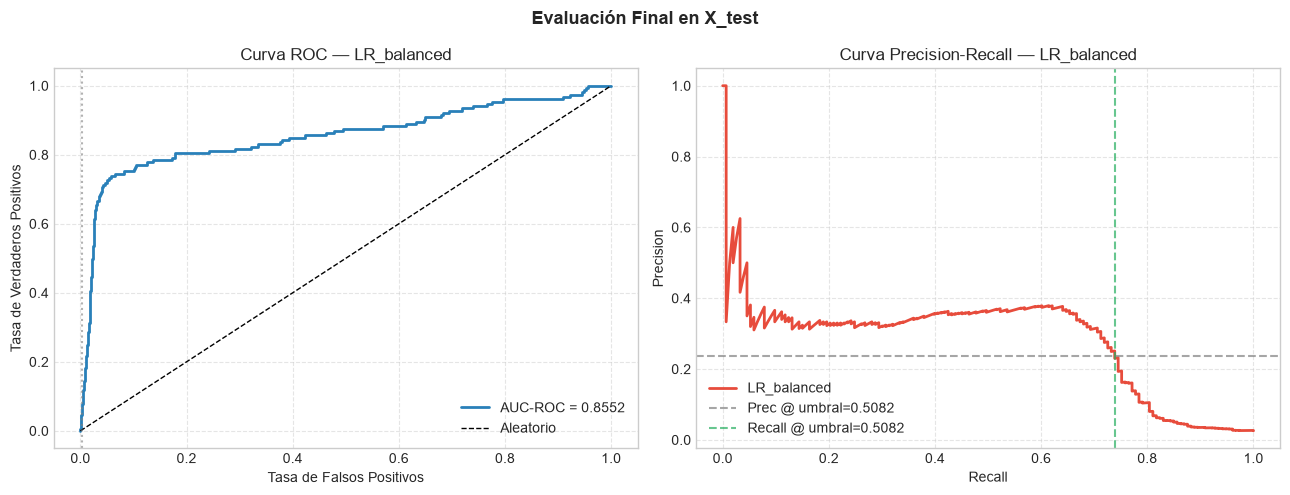

In [24]:
# (5) Curva ROC y Curva Precision-Recall evaluadas en X_test
fpr, tpr, _ = roc_curve(y_test, proba_test)
auc_roc      = roc_auc_score(y_test, proba_test)
prec_c, rec_c, thresh_c = precision_recall_curve(y_test, proba_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Curva ROC
axes[0].plot(fpr, tpr, color="#2980b9", lw=2, label=f"AUC-ROC = {auc_roc:.4f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Aleatorio")
axes[0].axvline(fpr[(np.abs(tpr - (proba_test >= umbral_final).mean())).argmin()],
                color="gray", linestyle=":", alpha=0.6)
axes[0].set_title(f"Curva ROC — {mejor_nombre}")
axes[0].set_xlabel("Tasa de Falsos Positivos")
axes[0].set_ylabel("Tasa de Verdaderos Positivos")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Curva Precision-Recall
axes[1].plot(rec_c, prec_c, color="#e74c3c", lw=2,
             label=f"{mejor_nombre}")
axes[1].axhline(precision_score(y_test, y_pred_test), color="gray",
                linestyle="--", alpha=0.7, label=f"Prec @ umbral={umbral_final}")
axes[1].axvline(recall_score(y_test, y_pred_test), color="#27ae60",
                linestyle="--", alpha=0.7, label=f"Recall @ umbral={umbral_final}")
axes[1].set_title(f"Curva Precision-Recall — {mejor_nombre}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Evaluación Final en X_test", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Interpretación de la evaluación final (holdout)

Sobre 6.000 transacciones no vistas (153 fraudulentas), el modelo final (Regresión Logística, umbral 0,5082) obtiene AUC-ROC 0,8552, Recall 0,7386, Precision 0,2359, F1 0,3576 y Accuracy 0,9323.

**Detección.** Identifica aproximadamente 113 de los 153 fraudes (73,9 %) y deja pasar unos 40.

**Costo operativo.** Genera alrededor de 366 falsas alarmas (≈6,3 % de las legítimas): de cada 4 alertas, solo 1 corresponde a un fraude real. Aun así, la Precision (0,2359) es unas 9 veces mayor que la prevalencia de fraude (2,55 %), es decir, mucho mejor que elegir al azar.

**Accuracy.** 0,9323 es menor que el 0,9745 de un clasificador que marque todo como legítimo, lo que confirma que no es una métrica adecuada en este problema.

**Frente a la validación cruzada.** El AUC-ROC (0,8552) y el Recall (0,7386) son algo menores que los obtenidos en validación (0,8837 y 0,8007). Con solo 153 fraudes en el conjunto de prueba, el Recall tiene un margen de error de unos ±7 puntos, y el umbral se afinó sobre otros datos. La diferencia es esperable y la evaluación en holdout es una estimación realista, no optimista.

**Curvas.** La curva ROC sube rápidamente hasta un TPR ≈ 0,75 con muy pocas falsas alarmas y luego crece lentamente; en la curva Precision-Recall, la Precision se mantiene entre 0,30 y 0,38 hasta un Recall ≈ 0,65 y cae al exigir más detección. Esto sugiere que una parte de los fraudes se comporta como transacciones legítimas y no se distingue con las variables disponibles.

**Implicación.** Si el banco prioriza detectar más fraudes, puede bajar el umbral a cambio de más falsas alarmas; si prioriza reducir la carga de revisión, puede subirlo.

# Sección 8: Matriz de Confusión e Intervalos de Confianza (Bootstrap)

Evaluación detallada de las predicciones del modelo final (`modelo_final`) con el umbral óptimo (`umbral_final`) sobre el conjunto de prueba `X_test`, incluyendo la matriz de confusión y la estimación de intervalos de confianza al 95 % mediante remuestreo Bootstrap.

### 8.1 Matriz de Confusión en X_test (Conteos absolutos y porcentajes por fila)

Verdaderos Positivos (VP): 113
Verdaderos Negativos (VN): 5481
Falsos Positivos    (FP): 366
Falsos Negativos    (FN): 40


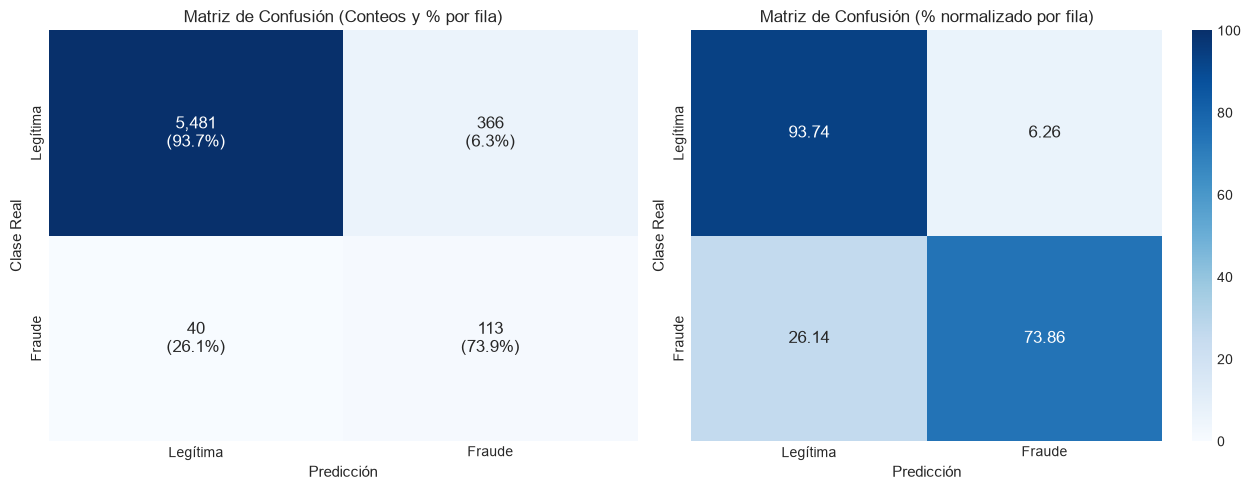

In [25]:
from sklearn.metrics import confusion_matrix

# (1) Predicciones sobre X_test con modelo_final y umbral_final
proba_test = modelo_final.predict_proba(X_test)[:, 1]
y_pred_test = (proba_test >= umbral_final).astype(int)

# Matriz de confusión: conteos absolutos y porcentajes normalizados por fila (clase real)
cm = confusion_matrix(y_test, y_pred_test)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

# Desglose e impresión de componentes
VN, FP, FN, VP = cm.ravel()
print(f"Verdaderos Positivos (VP): {VP}")
print(f"Verdaderos Negativos (VN): {VN}")
print(f"Falsos Positivos    (FP): {FP}")
print(f"Falsos Negativos    (FN): {FN}")

# Visualización con subplots (Conteos + % combinados y Porcentajes por fila)
etiquetas = ["Legítima", "Fraude"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Heatmap 1: Conteos absolutos y porcentaje fila combinado
annot_labels = np.array([
    [f"{cm[0,0]:,}\n({cm_pct[0,0]:.1f}%)", f"{cm[0,1]:,}\n({cm_pct[0,1]:.1f}%)"],
    [f"{cm[1,0]:,}\n({cm_pct[1,0]:.1f}%)", f"{cm[1,1]:,}\n({cm_pct[1,1]:.1f}%)"]
])
sns.heatmap(cm, annot=annot_labels, fmt="", cmap="Blues", cbar=False,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[0], annot_kws={"size": 12})
axes[0].set_title("Matriz de Confusión (Conteos y % por fila)", fontsize=12)
axes[0].set_xlabel("Predicción", fontsize=11)
axes[0].set_ylabel("Clase Real", fontsize=11)

# Heatmap 2: Porcentaje por fila (Recall por clase)
sns.heatmap(cm_pct, annot=True, fmt=".2f", cmap="Blues", cbar=True, vmin=0, vmax=100,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[1], annot_kws={"size": 12})
axes[1].set_title("Matriz de Confusión (% normalizado por fila)", fontsize=12)
axes[1].set_xlabel("Predicción", fontsize=11)
axes[1].set_ylabel("Clase Real", fontsize=11)

plt.tight_layout()
plt.show()

### 8.2 Intervalos de Confianza al 95 % para Recall y Precision (Bootstrap)

In [26]:
from sklearn.metrics import recall_score, precision_score

# (2) Bootstrap con 1000 remuestreos sobre X_test
n_bootstraps = 1000
rng = np.random.RandomState(42)

boot_recalls = []
boot_precisions = []

y_test_arr = np.array(y_test)
y_pred_arr = np.array(y_pred_test)
n_samples = len(y_test_arr)

for _ in range(n_bootstraps):
    indices = rng.randint(0, n_samples, n_samples)
    y_true_boot = y_test_arr[indices]
    y_pred_boot = y_pred_arr[indices]
    
    if y_true_boot.sum() > 0 and y_pred_boot.sum() > 0:
        boot_recalls.append(recall_score(y_true_boot, y_pred_boot))
        boot_precisions.append(precision_score(y_true_boot, y_pred_boot))

# Percentiles 2.5 y 97.5 para intervalo de confianza al 95%
ci_recall = (np.percentile(boot_recalls, 2.5), np.percentile(boot_recalls, 97.5))
ci_precision = (np.percentile(boot_precisions, 2.5), np.percentile(boot_precisions, 97.5))

df_ci = pd.DataFrame({
    "Métrica": ["Recall", "Precision"],
    "Valor en Test": [
        round(recall_score(y_test, y_pred_test), 4),
        round(precision_score(y_test, y_pred_test), 4)
    ],
    "IC 95% Inferior": [round(ci_recall[0], 4), round(ci_precision[0], 4)],
    "IC 95% Superior": [round(ci_recall[1], 4), round(ci_precision[1], 4)],
    "IC 95%": [
        f"[{ci_recall[0]:.4f}, {ci_recall[1]:.4f}]",
        f"[{ci_precision[0]:.4f}, {ci_precision[1]:.4f}]"
    ]
}).set_index("Métrica")

print(f"Intervalo de confianza 95% Recall:    [{ci_recall[0]:.4f}, {ci_recall[1]:.4f}]")
print(f"Intervalo de confianza 95% Precision: [{ci_precision[0]:.4f}, {ci_precision[1]:.4f}]")
display(df_ci)

Intervalo de confianza 95% Recall:    [0.6691, 0.8027]
Intervalo de confianza 95% Precision: [0.1991, 0.2740]


,Valor en Test,IC 95% Inferior,IC 95% Superior,IC 95%
Métrica,,,,
Recall,0.7386,0.6691,0.8027,"[0.6691, 0.8027]"
Precision,0.2359,0.1991,0.2740,"[0.1991, 0.2740]"


### Interpretación de la matriz de confusión e intervalos de confianza

Sobre las 6.000 transacciones del conjunto de prueba (5.847 legítimas y 153 fraudulentas), el modelo final con umbral 0,5082 produjo:

- **Verdaderos positivos (VP = 113):** fraudes detectados correctamente (73,9 % de los fraudes).
- **Falsos negativos (FN = 40):** fraudes que el modelo dejó pasar como legítimos (26,1 %). Es el error más costoso para el banco, porque cada uno es una pérdida económica no detectada.
- **Falsos positivos (FP = 366):** transacciones legítimas marcadas como sospechosas (6,3 % de las legítimas). Su costo es operativo: revisión manual y posible molestia al cliente.
- **Verdaderos negativos (VN = 5.481):** transacciones legítimas clasificadas correctamente (93,7 %).

**Carga de revisión.** El modelo genera 479 alertas (8,0 % de las transacciones), de las cuales 113 son fraudes reales: hay que revisar aproximadamente 4 alertas para encontrar un fraude. La Precision (23,6 %) es unas 9 veces mayor que la prevalencia de fraude (2,55 %), es decir, mucho mejor que seleccionar transacciones al azar.

**Intervalos de confianza (bootstrap, 95 %).** El Recall en el conjunto de prueba (0,7386) tiene un intervalo de [0,6691 – 0,8027] y la Precision (0,2359) de [0,1991 – 0,2740]. El Recall de 0,80 observado en validación cruzada cae dentro del intervalo, así que la diferencia con el holdout se explica por la variabilidad muestral (solo hay 153 fraudes) y no por una falla del modelo ni por fuga de datos.

**Equilibrio entre errores.** Con este umbral, el banco acepta revisar unas 3 falsas alarmas por cada fraude detectado a cambio de capturar cerca de 3 de cada 4 fraudes. Si la prioridad es perder menos fraudes, se puede bajar el umbral (más alertas y menos falsos negativos); si se quiere aliviar la carga de revisión, se puede subir.

#  Sección 9: predicciones sobre transacciones nuevas 

In [27]:

nuevas = pd.DataFrame([
    {"monto": 45.90, "hora_transaccion": 14, "distancia_ubicacion": 2.5, "frecuencia_transacciones": 2, "monto_promedio_cliente": 60.0, "dispositivo_nuevo": 0, "ubicacion_nueva": 0, "tipo_transaccion": "Compra", "canal": "POS", "metodo_autenticacion": "Tarjeta", "antiguedad_cliente_meses": 48},
    {"monto": 120.00, "hora_transaccion": 11, "distancia_ubicacion": 5.0, "frecuencia_transacciones": 1, "monto_promedio_cliente": 95.0, "dispositivo_nuevo": 0, "ubicacion_nueva": 0, "tipo_transaccion": "Pago", "canal": "Aplicación móvil", "metodo_autenticacion": "Biometría", "antiguedad_cliente_meses": 72},
    {"monto": 30.00, "hora_transaccion": 18, "distancia_ubicacion": 1.2, "frecuencia_transacciones": 3, "monto_promedio_cliente": 40.0, "dispositivo_nuevo": 0, "ubicacion_nueva": 0, "tipo_transaccion": "Compra", "canal": "Web", "metodo_autenticacion": "Clave", "antiguedad_cliente_meses": 24},
    {"monto": 950.00, "hora_transaccion": 2, "distancia_ubicacion": 180.0, "frecuencia_transacciones": 8, "monto_promedio_cliente": 70.0, "dispositivo_nuevo": 1, "ubicacion_nueva": 1, "tipo_transaccion": "Transferencia", "canal": "Web", "metodo_autenticacion": "Clave", "antiguedad_cliente_meses": 6},
    {"monto": 600.00, "hora_transaccion": 3, "distancia_ubicacion": 95.0, "frecuencia_transacciones": 6, "monto_promedio_cliente": 55.0, "dispositivo_nuevo": 1, "ubicacion_nueva": 1, "tipo_transaccion": "Retiro", "canal": "Cajero", "metodo_autenticacion": "Clave", "antiguedad_cliente_meses": 10},
    {"monto": 1500.00, "hora_transaccion": 0, "distancia_ubicacion": 250.0, "frecuencia_transacciones": 10, "monto_promedio_cliente": 80.0, "dispositivo_nuevo": 1, "ubicacion_nueva": 1, "tipo_transaccion": "Transferencia", "canal": "Aplicación móvil", "metodo_autenticacion": "Token", "antiguedad_cliente_meses": 3},
])
nuevas["prob_fraude"] = modelo_final.predict_proba(nuevas)[:, 1].round(4)
nuevas["clasificacion"] = np.where(nuevas["prob_fraude"] >= umbral_final,
                                   "Transacción potencialmente fraudulenta", "Transacción legítima")
display(nuevas[["monto", "hora_transaccion", "tipo_transaccion", "canal", "dispositivo_nuevo",
                "ubicacion_nueva", "prob_fraude", "clasificacion"]])

,monto,hora_transaccion,tipo_transaccion,canal,dispositivo_nuevo,ubicacion_nueva,prob_fraude,clasificacion
0,45.9,14,Compra,POS,0,0,0.1366,Transacción legítima
1,120.0,11,Pago,Aplicación móvil,0,0,0.0899,Transacción legítima
2,30.0,18,Compra,Web,0,0,0.2920,Transacción legítima
3,950.0,2,Transferencia,Web,1,1,0.9998,Transacción potencialmente fraudulenta
4,600.0,3,Retiro,Cajero,1,1,0.9935,Transacción potencialmente fraudulenta
5,1500.0,0,Transferencia,Aplicación móvil,1,1,1.0000,Transacción potencialmente fraudulenta


### Interpretación de las predicciones sobre transacciones nuevas

Se clasificaron seis transacciones creadas manualmente (no pertenecen al dataset): tres con perfil habitual y tres con perfil de riesgo.

**Perfil habitual.** Las tres transacciones diurnas, cercanas a la ubicación del cliente, con montos entre 30 y 120 USD y sin dispositivo ni ubicación nuevos recibieron probabilidades de fraude entre 0,0899 y 0,2920, todas por debajo del umbral (0,5082), y se clasificaron como "Transacción legítima".

**Perfil de riesgo.** Las tres transacciones de madrugada (0 a 3 h), con dispositivo y ubicación nuevos, distancias de 95 a 250 km y montos de 600 a 1.500 USD recibieron probabilidades entre 0,9935 y 1,0000 y se clasificaron como "Transacción potencialmente fraudulenta".

**Coherencia con el EDA.** El modelo reacciona a las señales que el análisis exploratorio había identificado: ubicación nueva (17,63 % de fraude), dispositivo nuevo (13,72 %), horario de madrugada, transferencias y retiros, y canales Web y Cajero. La transacción 2 (compra por Web con clave) obtuvo la mayor probabilidad entre las legítimas (0,2920), lo que concuerda con que Web y Clave presentan tasas de fraude superiores al promedio.

**Alcance.** Estos ejemplos son casos claros, elegidos para ilustrar el funcionamiento. Los casos difíciles son los fraudes que se parecen a una transacción normal, y por eso el Recall en prueba es 73,9 % y no 100 %. Además, como el modelo se entrenó con `class_weight="balanced"`, sus probabilidades no están calibradas: deben leerse como un puntaje de riesgo, no como la probabilidad real de fraude.

#  Sección 10: prototipo de clasificación y guardado del modelo 

In [28]:

import joblib

def clasificar_transaccion(monto, hora_transaccion, distancia_ubicacion, frecuencia_transacciones,
                           monto_promedio_cliente, dispositivo_nuevo, ubicacion_nueva,
                           tipo_transaccion, canal, metodo_autenticacion, antiguedad_cliente_meses,
                           modelo=modelo_final, umbral=umbral_final):
    fila = pd.DataFrame([{
        "monto": monto, "hora_transaccion": hora_transaccion, "distancia_ubicacion": distancia_ubicacion,
        "frecuencia_transacciones": frecuencia_transacciones, "monto_promedio_cliente": monto_promedio_cliente,
        "dispositivo_nuevo": dispositivo_nuevo, "ubicacion_nueva": ubicacion_nueva,
        "tipo_transaccion": tipo_transaccion, "canal": canal, "metodo_autenticacion": metodo_autenticacion,
        "antiguedad_cliente_meses": antiguedad_cliente_meses}])
    prob = float(modelo.predict_proba(fila)[0, 1])
    etiqueta = "Transacción potencialmente fraudulenta" if prob >= umbral else "Transacción legítima"
    return etiqueta, prob

print(clasificar_transaccion(35.0, 15, 3.0, 2, 50.0, 0, 0, "Compra", "POS", "Tarjeta", 40))
print(clasificar_transaccion(1200.0, 2, 200.0, 9, 60.0, 1, 1, "Transferencia", "Web", "Clave", 4))

joblib.dump({"modelo": modelo_final, "umbral": umbral_final}, "modelo_fraude.joblib")
print("Modelo guardado en modelo_fraude.joblib")

('Transacción legítima', 0.1416090275681757)
('Transacción potencialmente fraudulenta', 0.9999359921140062)
Modelo guardado en modelo_fraude.joblib


### Interpretación del prototipo de clasificación

La función `clasificar_transaccion()` recibe las 11 características de una transacción, las convierte en un registro y lo procesa con el pipeline completo (imputación, escalado y codificación incluidos), por lo que no requiere ningún preprocesamiento manual. Devuelve la etiqueta ("Transacción legítima" o "Transacción potencialmente fraudulenta") junto con la probabilidad estimada, usando el umbral de decisión 0,5082.

En las dos pruebas, una compra de 35 USD en POS con tarjeta, en horario diurno y cerca del domicilio, se clasificó como legítima (probabilidad 0,1416); una transferencia de 1.200 USD a las 2 h, a 200 km, con dispositivo y ubicación nuevos y 9 transacciones en 24 horas, se clasificó como potencialmente fraudulenta (0,9999).

El modelo y su umbral se guardaron en `modelo_fraude.joblib`, lo que permite reutilizarlo sin reentrenar y es el primer paso para integrarlo en un sistema de monitoreo.

## 11. Conclusiones y recomendaciones


**Mejor modelo.** El modelo seleccionado fue la Regresión Logística con `class_weight="balanced"` y umbral 0,5082. En validación cruzada logró el mayor Recall (0,8007) y un AUC-ROC de 0,8837. Random Forest quedó prácticamente empatado al ajustar su umbral (Precision 0,2701 frente a 0,2748), y se eligió la Regresión Logística por ser más simple y explicable. El Árbol de Decisión y las variantes con SMOTE no aportaron mejoras.

**Métricas que sustentan la selección.** El criterio principal fue detectar la mayor cantidad de fraudes (minimizar falsos negativos) exigiendo Recall ≥ 0,80 y, bajo esa condición, maximizar la Precision. En el conjunto de prueba el modelo obtuvo AUC-ROC 0,8552, Recall 0,7386 (IC 95 %: 0,67–0,80), Precision 0,2359 y F1 0,3576: detectó 113 de 153 fraudes, dejó pasar 40 y generó 366 falsas alarmas. La Accuracy (0,9323) no se usó para decidir, porque clasificar todo como legítimo daría 0,9745.

**Limitaciones.**
- El dataset es sintético: las relaciones entre variables y fraude las define el generador, por lo que los resultados no son extrapolables a datos reales.
- Solo hay 153 fraudes en el conjunto de prueba, lo que da intervalos de confianza amplios (±6 puntos en el Recall).
- La Precision es baja: por cada fraude detectado hay unas 3 falsas alarmas.
- Un porcentaje de los fraudes imita el comportamiento legítimo y no es separable con las variables disponibles.
- Los hiperparámetros se fijaron sin una búsqueda exhaustiva, y la división fue aleatoria, no temporal.
- Las probabilidades no están calibradas (efecto de `class_weight`): sirven como puntaje de riesgo.

**Uso en un sistema real de monitoreo.**
- Puntuar cada transacción en línea y enviar a revisión humana las que superen el umbral, priorizando por probabilidad.
- Definir el umbral según el costo de un fraude no detectado frente al de una revisión innecesaria, y ajustarlo periódicamente.
- Monitorear Recall, Precision y la distribución de las variables para detectar deterioro del modelo (data drift).
- Reentrenar de forma periódica con los casos confirmados por los analistas y validar con una división temporal.
- Combinarlo con reglas de negocio (por ejemplo, dispositivo nuevo, ubicación nueva y madrugada) y calibrar las probabilidades antes de usarlas como estimaciones.

**Conclusión general.** El prototipo demuestra que un modelo de clasificación supervisada, entrenado con técnicas que evitan la fuga de datos y tratan el desbalance, puede priorizar transacciones sospechosas y servir de apoyo al monitoreo, siempre con revisión humana.